<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 18: RNN, LSTM and GRU Hyperparameter Experimentation

1. Tokenise and pad reviews; add an embedding layer

In [1]:

!pip -q install keras-tuner

import tensorflow as tf
import keras_tuner as kt
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

tf.keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=3000)

# Small dataset for fast execution
x_train, y_train = x_train[:1500], y_train[:1500]
x_test, y_test = x_test[:500], y_test[:500]

x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train,maxlen=100)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test,maxlen=100)

print("Training:",x_train.shape)
print("Testing:",x_test.shape)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training: (1500, 100)
Testing: (500, 100)


2. Define a model-builder function for RNN, LSTM and GRU

In [2]:

def build_model(hp):
    cell = hp.Choice('cell',['SimpleRNN','LSTM','GRU'])
    units = hp.Choice('units',[16,32])
    layers = hp.Int('layers',1,2)
    dropout = hp.Choice('dropout',[0.0,0.2])
    emb = hp.Choice('embedding',[16,32])
    lr = hp.Choice('lr',[0.001,0.005])

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(100,)),
        tf.keras.layers.Embedding(3000,emb)
    ])

    cell_class = getattr(tf.keras.layers,cell)

    for i in range(layers):
        model.add(cell_class(units,dropout=dropout,
                             return_sequences=(i<layers-1)))

    model.add(tf.keras.layers.Dense(1,activation='sigmoid'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

print("Model builder created")


Model builder created


3. Tune hyperparameters using KerasTuner

In [3]:

tuners = {}
times = {}

for cell in ['SimpleRNN','LSTM','GRU']:
    def builder(hp, cell=cell):
        hp.Fixed('cell',cell)
        return build_model(hp)

    tuner = kt.RandomSearch(
        builder,
        objective='val_accuracy',
        max_trials=3,
        overwrite=True,
        directory='rnn_tuning',
        project_name=cell
    )

    start = time.time()
    tuner.search(x_train,y_train,epochs=2,
                 validation_split=0.2,
                 batch_size=64,verbose=0)

    times[cell] = round(time.time()-start,2)
    tuners[cell] = tuner
    print(cell,"tuning completed")


SimpleRNN tuning completed
LSTM tuning completed
GRU tuning completed


4. Report the best configuration for each cell type

In [5]:

for cell,tuner in tuners.items():
    best_hp = tuner.get_best_hyperparameters(1)[0]
    print("\n",cell,"Best Configuration:")
    print(best_hp.values)



 SimpleRNN Best Configuration:
{'cell': 'SimpleRNN', 'units': 32, 'layers': 1, 'dropout': 0.2, 'embedding': 16, 'lr': 0.005}

 LSTM Best Configuration:
{'cell': 'LSTM', 'units': 32, 'layers': 2, 'dropout': 0.2, 'embedding': 16, 'lr': 0.005}

 GRU Best Configuration:
{'cell': 'GRU', 'units': 16, 'layers': 2, 'dropout': 0.0, 'embedding': 32, 'lr': 0.005}


5. Compare accuracy, parameter count and training time

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 20 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


    Model  Accuracy (%)  Parameters  Tuning Time (s)
SimpleRNN          50.2       49601            18.00
     LSTM          66.6       62625            28.12
      GRU          61.6      100049            29.95


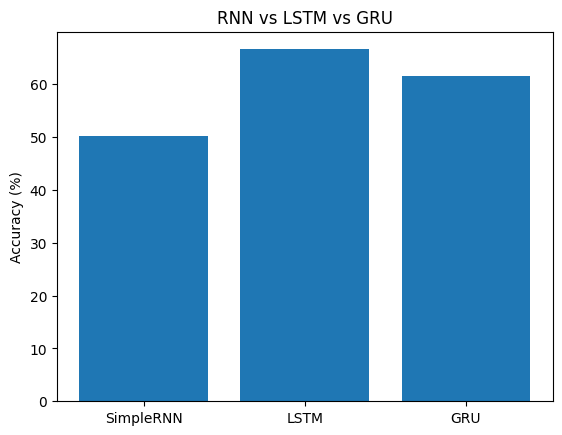

In [6]:

results = []

for cell,tuner in tuners.items():
    model = tuner.get_best_models(1)[0]
    loss,acc = model.evaluate(x_test,y_test,verbose=0)

    results.append([
        cell,round(acc*100,2),
        model.count_params(),times[cell]
    ])

df = pd.DataFrame(results,columns=[
    'Model','Accuracy (%)','Parameters','Tuning Time (s)'
])

print(df.to_string(index=False))

plt.bar(df['Model'],df['Accuracy (%)'])
plt.ylabel('Accuracy (%)')
plt.title('RNN vs LSTM vs GRU')
plt.show()
